# 03 - Dataset design and splits

In notebook 01 we built a large cube of data with 105 months x (1000lat x 910lon) pixels at a resolution of 20 meters. Before moving to the training of the model, we have to split the generated cube into samples and decide which months and pixels each stage (train, validation and test) will have access to.
We define a sample as a reference month t0, such that the model sees the previous 12 months and predicts the three following ones' NDMI anomaly. In other words, for a sample month t0, the trained model will be fed data from (t0-11, t0-10, ..., t0) and will target NDMI anomaly at (t0+1, t0+2, t0+3)

We will train the model on the 2017-2021 split, validate it on 2022, and finally test it on 2023-2025, which includes the drought of 2022-2024.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import pandas as pd
import xarray as xr
import numpy as np


from src.dataset import make_samples, land_mask, SPLITS, holdout_mask
from src.paths import PROCESSED

## 1. Load the cube

Load the cube (lazily, to avoid the full several GBs load)

In [2]:
cube = xr.open_zarr(PROCESSED / "cube.zarr")
cube

<xarray.Dataset> Size: 7GB
Dimensions:                (lat: 1000, lon: 910, time: 105)
Coordinates:
  * lat                    (lat) float64 8kB 42.1 42.1 42.1 ... 41.92 41.92
  * lon                    (lon) float64 7kB 2.97 2.97 2.971 ... 3.189 3.19 3.19
  * time                   (time) datetime64[ns] 840B 2017-04-01 ... 2025-12-01
    month                  (time) int64 840B dask.array<chunksize=(105,), meta=np.ndarray>
Data variables: (12/37)
    aspect                 (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    clear_count            (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    e                      (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    eastness               (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    elevation              (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    irrigated              (lat, lon) uint8 910kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    ...                     ...
    spi6                   (time, lat, lon) float64 764MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    swvl1                  (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    swvl2                  (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    t2m                    (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    tp                     (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    valid_mask             (time, lat, lon) uint8 96MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>

## 2. Time split

Make samples with the defined splits

In [3]:
samples = make_samples(cube.time)
samples.groupby("split", sort = False).t0.agg(["count", "min", "max"])

,count,min,max
split,,,
train,43,2018-03-01,2021-09-01
val,10,2021-12-01,2022-09-01
test,34,2022-12-01,2025-09-01


We have 43 samples for training, 10 samples for validation, and 34 samples for testing. Note the gaps:
- The first eleven months have no sample because a full 12-month input window is not available
- The last three months have no sample because there's not enough future data to fill the 3-month target window
- October - November of 2021 and 2022 are dropped because their targets would fall in two different splits, thus leaking information

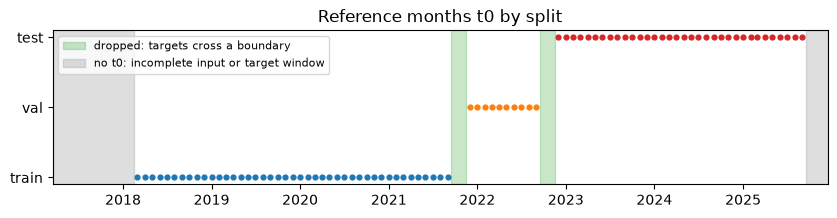

In [4]:
times = cube.indexes["time"]
colours = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
half = pd.Timedelta(days=15)

fig, ax = plt.subplots(figsize=(10, 2))
for split, g in samples.groupby("split", sort=False):
    ax.scatter(g.t0, [split] * len(g), color=colours[split], s=12)

# months between the first and last t0 that were dropped by the split rule
first, last = samples.t0_idx.min(), samples.t0_idx.max()
candidates = times[first : last + 1]
dropped = pd.Series(candidates.difference(samples.t0))
run_id = (dropped.diff() > pd.Timedelta(days=31)).cumsum()
for k, run in dropped.groupby(run_id):
    ax.axvspan(run.iloc[0] - half, run.iloc[-1] + half,
               color="tab:green", alpha=0.25,
               label="dropped: targets cross a boundary" if k == 0 else None)

# edges: no full input window at the start, no full target window at the end
ax.axvspan(times[0] - half, times[first - 1] + half, color="tab:gray", alpha=0.25,
           label="no t0: incomplete input or target window")
ax.axvspan(times[last + 1] - half, times[-1] + half, color="tab:gray", alpha=0.25)

ax.set_xlim(times[0] - half, times[-1] + half)
ax.set_title("Reference months t0 by split")
ax.legend(loc="upper left", fontsize=8)
plt.show()


Each dot represents one sample along the available data time, with a color indicating which split it is assigned to. In green we mark the samples dropped because their targets would fall in two splits, and in grey those that lack enough previous months or target window.


## 3. Land mask

See which pixels are masked as land and thus can be fed to the model. We exclude, on the one hand, water and built-up surfaces (such as roads or buildings), since their NDMI signals do not reflect climate-driven vegetation moisture. And, on the other one, those pixels that have never been observed and thus are not present in the satellite data (due to clouds, etc).

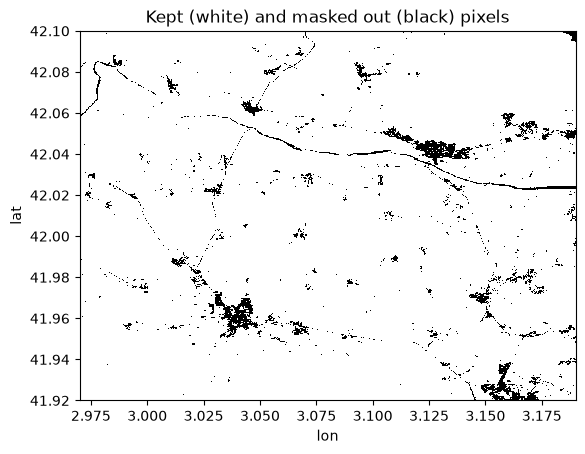

Percentage of pixels kept: 96.3%


In [5]:
land = land_mask(cube)
land.plot(cmap="Greys_r", add_colorbar = False)
plt.title("Kept (white) and masked out (black) pixels")
plt.show()

print(f"Percentage of pixels kept: {float(land.mean()):.1%}")

## 4. Spatial holdout

Neighbouring pixels most commonly share weather, soil type and land use, and thus their NDMI values change together. Were test pixels to sit just next to training ones, this spatial autocorrelation could be learnt by the model and potentially inflate the obtained score, and thus overstate how well the model can generalise to new places. To avoid that, a contiguous block of pixels is held out of training, validation and normalisation, so that test scores on this block show how the model would perform on new places.
We choose to hold out the easternmost strip of the selected area (around 20% of it, properly rounded to match the tiles used in convolutional models in order to avoid leakages at the boundary). 

In [6]:
frac = .2
tile = 64

holdout = holdout_mask(cube, frac = frac, tile = tile)

print(f"share of land pixels held out: {float((land & holdout).sum() / land.sum()):.1%}")

share of land pixels held out: 22.2%


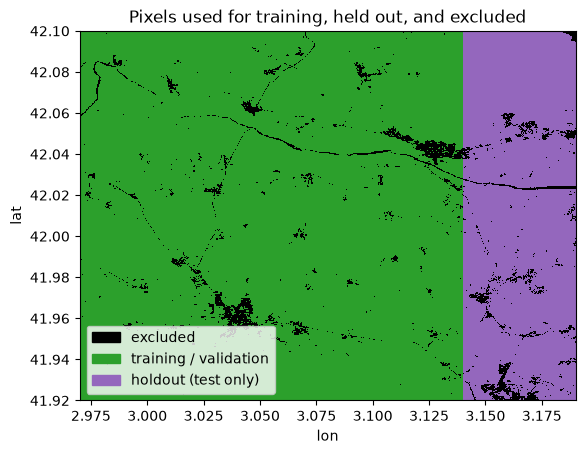

In [7]:
groups = xr.where(~land, 0, xr.where(holdout, 2, 1)) 
labels = ["excluded",
          "training / validation",
          "holdout (test only)"]
colours = ["black", "tab:green", "tab:purple"]


groups.plot(cmap = ListedColormap(colours), add_colorbar = False, vmin = -0.5, vmax = 2.5)
plt.legend(handles = [Patch(color = c, label = l) for c, l in zip(colours, labels)], loc = "lower left")
plt.title("Pixels used for training, held out, and excluded")
plt.show()

In [8]:
names = dict(zip(cube.landcover.attrs["flag_values"],
                 cube.landcover.attrs["flag_meanings"].split()))

lc  = pd.Series(cube.landcover.values.ravel()).map(names)    # class name per pixel
irr = cube.irrigated.values.ravel().astype(bool)

# split cropland and grassland by the irrigated flag
label = lc.where(~irr, lc + ", irrigated")
label = label.where(irr | ~lc.isin(["cropland", "grassland"]), lc + ", rainfed")

areas = {"holdout": (land & holdout).values.ravel(),
         "rest":    (land & ~holdout).values.ravel()}

shares = pd.DataFrame({area: label[sel].value_counts(normalize=True)
                       for area, sel in areas.items()}).fillna(0)

(shares * 100).round(1).sort_index()


,holdout,rest
bare_sparse,0.4,0.2
"cropland, irrigated",13.0,8.9
"cropland, rainfed",17.8,38.9
"grassland, irrigated",0.8,0.5
"grassland, rainfed",15.9,14.2
herbaceous_wetland,0.4,0.0
shrubland,4.9,4.2
tree_cover,46.8,33.0


The choice of holding out the 20% easternmost strip is a convention, and is taken before any training. Two things must be noted from the differences in land cover shares between the two strips: 

- Compared to the rest of the area, the holdout strip contains less total amount of cropland (30.8% vs 47.8%), but more irrigated corpland (13.0% vs 8.9%), so the test on the holdout pixels more irrigated fields, whose response to droughts are very different from that of rainfed ones. 

- While forests are over-represented in the holdout area (46.8% vs 33.0%), rainfed croplands are under-represented (17.8% vs 38.9%). As a consequence, differences in forecasting accuracy between holdout and training areas can partly reflect land cover, not only the unseen location.

Furthermore, irrigated and rainfed labels come from the heuristic mask (NDMI > 0.25) imposed on notebook 01, rather than from ground truth, so might contain some errors.